# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [ ]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [ ]:
# Guardar la caché junto al notebook para reutilizar el dataset sin conexión.
from pathlib import Path

carpeta_datos = Path("datasets")
carpeta_datos.mkdir(exist_ok=True)
data = sns.load_dataset("titanic", data_home=str(carpeta_datos))


In [ ]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Conjunto de datos Titanic:


In [ ]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [ ]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [ ]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [ ]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [ ]:
# Comparar ambas técnicas sobre la misma variable para aislar sus diferencias.
mapa_sex = dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_),
))
encoder_sex = OneHotEncoder(sparse_output=False, handle_unknown="ignore", dtype=int)
sex_onehot = pd.DataFrame(
    encoder_sex.fit_transform(data[["sex"]]),
    columns=encoder_sex.get_feature_names_out(["sex"]),
    index=data.index,
)
comparacion = pd.concat([data[["sex", "sex_label"]], sex_onehot], axis=1)
display(comparacion.drop_duplicates().sort_values("sex").reset_index(drop=True))
print("Correspondencia de LabelEncoder:", mapa_sex)
print(
    "LabelEncoder asigna un entero a cada categoría y produce una sola columna. "
    "En scikit-learn está pensado para la variable objetivo y. Si se aplica a "
    "una característica con más de dos categorías, sus números pueden introducir "
    "un orden o distancias que no existen. OneHotEncoder crea una columna "
    "binaria por categoría, sin imponer ese orden, a costa de más columnas. "
    "Para sex, que es binaria, una sola columna 0/1 es suficiente en muchos modelos. "
    "En la introducción se usó pd.get_dummies para embarked: también genera "
    "indicadores, pero OneHotEncoder aprende las categorías con fit y reutiliza "
    "el mismo esquema con transform."
)


,sex,sex_label,sex_female,sex_male
0,female,0,1,0
1,male,1,0,1


Correspondencia de LabelEncoder: {'female': np.int64(0), 'male': np.int64(1)}
LabelEncoder asigna un entero a cada categoría y produce una sola columna. En scikit-learn está pensado para la variable objetivo y. Si se aplica a una característica con más de dos categorías, sus números pueden introducir un orden o distancias que no existen. OneHotEncoder crea una columna binaria por categoría, sin imponer ese orden, a costa de más columnas. Para sex, que es binaria, una sola columna 0/1 es suficiente en muchos modelos. En la introducción se usó pd.get_dummies para embarked: también genera indicadores, pero OneHotEncoder aprende las categorías con fit y reutiliza el mismo esquema con transform.


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

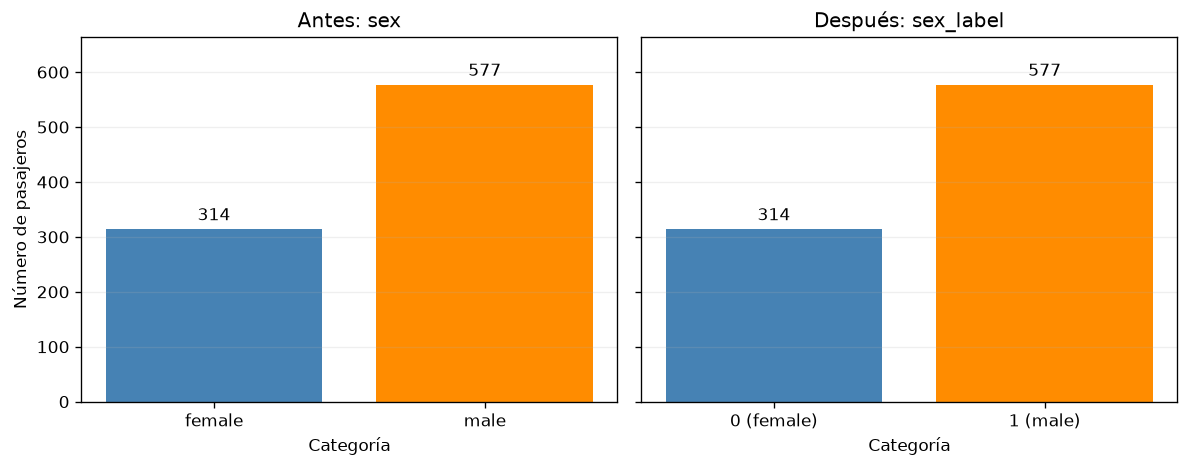

La codificación cambia las etiquetas, pero conserva exactamente las frecuencias.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Reindexar asegura que cada color represente la misma categoría en ambos paneles.
categorias = label_encoder.classes_
codigos = label_encoder.transform(categorias)
frecuencias_originales = data["sex"].value_counts().reindex(categorias, fill_value=0)
frecuencias_codificadas = data["sex_label"].value_counts().reindex(codigos, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
colores = ["steelblue", "darkorange"]
for ax, etiquetas, frecuencias, titulo in [
    (axes[0], categorias, frecuencias_originales, "Antes: sex"),
    (axes[1], [f"{codigo} ({nombre})" for codigo, nombre in zip(codigos, categorias)],
     frecuencias_codificadas, "Después: sex_label"),
]:
    barras = ax.bar(etiquetas, frecuencias.to_numpy(), color=colores)
    ax.bar_label(barras, padding=3)
    ax.set(title=titulo, xlabel="Categoría")
    ax.set_ylim(0, frecuencias_originales.max() * 1.15)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Número de pasajeros")
fig.tight_layout()
plt.show()

assert np.array_equal(frecuencias_originales.to_numpy(), frecuencias_codificadas.to_numpy())
print("La codificación cambia las etiquetas, pero conserva exactamente las frecuencias.")


### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [ ]:
# Usar el estimador de sklearn y conservar el índice para alinear las filas.
encoder_class = OneHotEncoder(sparse_output=False, handle_unknown="ignore", dtype=int)
class_onehot = pd.DataFrame(
    encoder_class.fit_transform(data[["class"]]),
    columns=encoder_class.get_feature_names_out(["class"]),
    index=data.index,
)
display(pd.concat([data[["class"]], class_onehot], axis=1).drop_duplicates())
display(class_onehot.sum().rename("Pasajeros por clase").to_frame())
assert class_onehot.sum(axis=1).eq(1).all()

print(
    "Cada pasajero tiene un 1 en su clase y un 0 en las demás. OneHotEncoder "
    "permite aprender un efecto independiente para cada clase sin asumir "
    "distancias iguales entre First, Second y Third. Aunque class tiene un "
    "orden natural, tratarla como 0, 1, 2 impone una relación numérica que "
    "puede ser demasiado restrictiva para un modelo lineal. Si se quisiera "
    "representar explícitamente el orden, se usaría OrdinalEncoder con las "
    "categorías ordenadas, no LabelEncoder para características. "
    "handle_unknown='ignore' mantiene las mismas columnas en datos nuevos; "
    "una categoría desconocida se representa con ceros en todo su bloque."
)


,class,class_First,class_Second,class_Third
0,Third,0,0,1
1,First,1,0,0
9,Second,0,1,0


,Pasajeros por clase
class_First,216
class_Second,184
class_Third,491


Cada pasajero tiene un 1 en su clase y un 0 en las demás. OneHotEncoder permite aprender un efecto independiente para cada clase sin asumir distancias iguales entre First, Second y Third. Aunque class tiene un orden natural, tratarla como 0, 1, 2 impone una relación numérica que puede ser demasiado restrictiva para un modelo lineal. Si se quisiera representar explícitamente el orden, se usaría OrdinalEncoder con las categorías ordenadas, no LabelEncoder para características. handle_unknown='ignore' mantiene las mismas columnas en datos nuevos; una categoría desconocida se representa con ceros en todo su bloque.


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [ ]:
# Ejemplo reproducible: predecir survived usando solo las categorías originales.
# Dividir ANTES de aprender la imputación y la codificación evita fuga de información.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

X = data[categorical_cols].copy()
y = data["survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)

pipeline_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocesamiento = ColumnTransformer([
    ("categoricas", pipeline_categorico, categorical_cols),
])
modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=42)),
])
modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)

encoder_ajustado = modelo.named_steps["preprocesamiento"].named_transformers_["categoricas"].named_steps["onehot"]
print("Columnas aprendidas solo en entrenamiento:")
print(encoder_ajustado.get_feature_names_out(categorical_cols))
print(f"Exactitud en prueba: {accuracy_score(y_test, predicciones):.3f}")
print(f"Exactitud balanceada en prueba: {balanced_accuracy_score(y_test, predicciones):.3f}")
print("Valores faltantes en las variables originales:")
display(X.isna().sum().rename("Faltantes").to_frame())

print(
    "Elegiría OneHotEncoder para sex y embarked, porque son categorías "
    "nominales, y también para class como punto de partida, para permitir "
    "efectos independientes. Su baja cardinalidad hace que el número de columnas "
    "sea pequeño; para variables binarias también es válida una codificación "
    "0/1. Imputo los valores faltantes con la moda aprendida exclusivamente "
    "en entrenamiento. No incluyo sex_label ni los indicadores previos de "
    "embarked, para no duplicar características, ni alive, que revela el objetivo. "
    "survived ya es una variable objetivo binaria y no necesita LabelEncoder. "
    "Si el modelo justificara aprovechar el orden de class, compararía "
    "OrdinalEncoder con OneHotEncoder mediante validación cruzada sobre "
    "entrenamiento. Las métricas anteriores ilustran el funcionamiento del "
    "pipeline; no demuestran que una codificación sea superior a todas las demás."
)


,Faltantes
sex,0
embarked,2
class,0


Columnas aprendidas solo en entrenamiento:
['sex_female' 'sex_male' 'embarked_C' 'embarked_Q' 'embarked_S'
 'class_First' 'class_Second' 'class_Third']
Exactitud en prueba: 0.765
Exactitud balanceada en prueba: 0.752
Valores faltantes en las variables originales:
Elegiría OneHotEncoder para sex y embarked, porque son categorías nominales, y también para class como punto de partida, para permitir efectos independientes. Su baja cardinalidad hace que el número de columnas sea pequeño; para variables binarias también es válida una codificación 0/1. Imputo los valores faltantes con la moda aprendida exclusivamente en entrenamiento. No incluyo sex_label ni los indicadores previos de embarked, para no duplicar características, ni alive, que revela el objetivo. survived ya es una variable objetivo binaria y no necesita LabelEncoder. Si el modelo justificara aprovechar el orden de class, compararía OrdinalEncoder con OneHotEncoder mediante validación cruzada sobre entrenamiento. Las métricas a